# Stock Simulator Demo

This notebook demonstrates each function from the stock simulator module.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stock_simulator import (
    wiener_process,
    simulate_gbm,
    calculate_moving_average,
    calculate_rolling_volatility,
    simulate_garch,
    train_garch_rolling_forecast,
)

Wiener process shape: (50, 3)


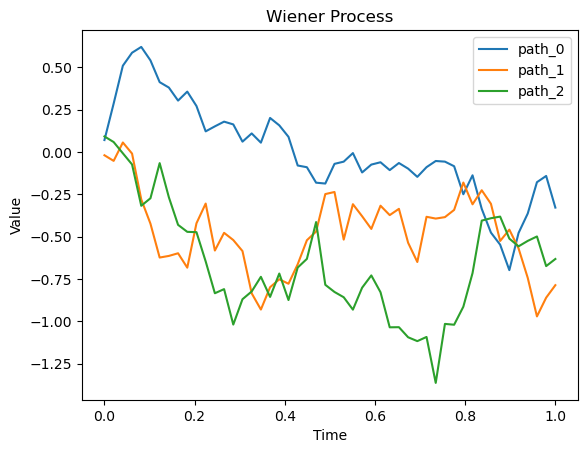

In [3]:
# 1) Wiener process
W, times = wiener_process(n_steps=50, T=1.0, n_paths=3)
print("Wiener process shape:", W.shape)
plt.plot(times, W[:, 0], label="path_0")
plt.plot(times, W[:, 1], label="path_1")
plt.plot(times, W[:, 2], label="path_2")
plt.title("Wiener Process")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.show()

              path_0      path_1      path_2
time                                        
0.000000  100.000000  100.000000  100.000000
0.003968  100.500478  102.779721   95.457078
0.007937   98.886994  101.214293   94.661834
0.011905  100.081982  100.843587   98.358828
0.015873  101.595133  102.105444   99.053939


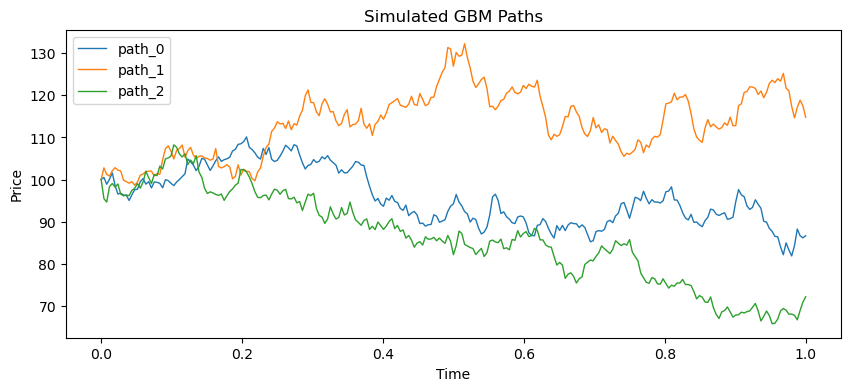

In [4]:
# 2) Geometric Brownian Motion
sim_df = simulate_gbm(S0=100.0, mu=0.08, sigma=0.25, T=1.0, n_steps=252, n_paths=3, seed=42)
print(sim_df.head())
sim_df.plot(figsize=(10, 4), lw=1.0)
plt.title("Simulated GBM Paths")
plt.xlabel("Time")
plt.ylabel("Price")
plt.show()

              path_0      path_1     path_2
time                                       
0.007937   99.795824  101.331338  96.706304
0.011905   99.823151  101.612534  96.159247
0.015873  100.188036  101.387774  97.358201
0.019841  100.072391  101.925290  98.538877
0.023810   98.897903  102.390522  98.734241


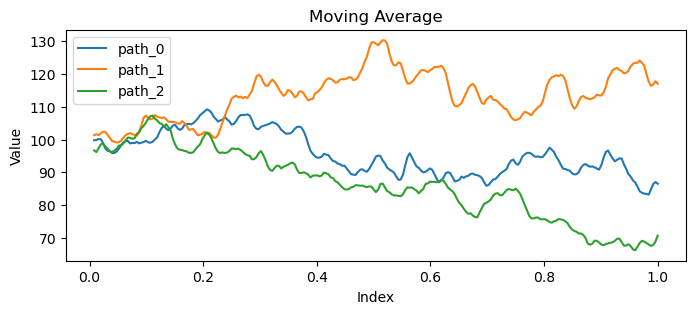

In [5]:
# 3) Moving average
prices = sim_df
ma = calculate_moving_average(prices, window_size=3)
print(ma.head())
ma.plot(figsize=(8, 3))
plt.title("Moving Average")
plt.xlabel("Index")
plt.ylabel("Value")
plt.show()

          path_0 volatiltity  path_1 volatiltity  path_2 volatiltity
time                                                                
0.011905            0.233018            0.350903            0.674257
0.015873            0.273183            0.221455            0.377551
0.019841            0.404345            0.130126            0.379303
0.023810            0.379312            0.148095            0.145766
0.027778            0.265904            0.104064            0.253260


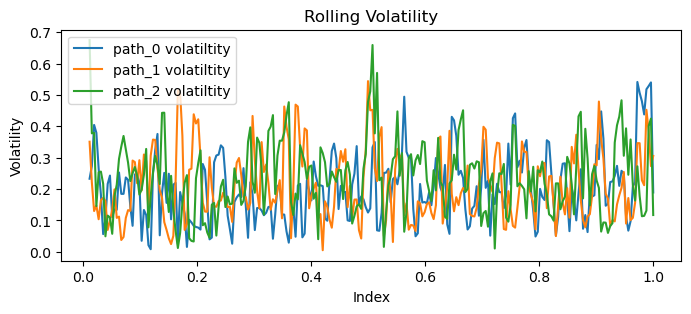

In [6]:
# 4) Rolling volatility
vol = calculate_rolling_volatility(prices, window_size=3)
print(vol.head())
vol.plot(figsize=(8, 3))
plt.title("Rolling Volatility")
plt.xlabel("Index")
plt.ylabel("Volatility")
plt.show()

       Path_0
0  100.000000
1  100.005130
2  104.490328
3  103.341383
4  103.466083


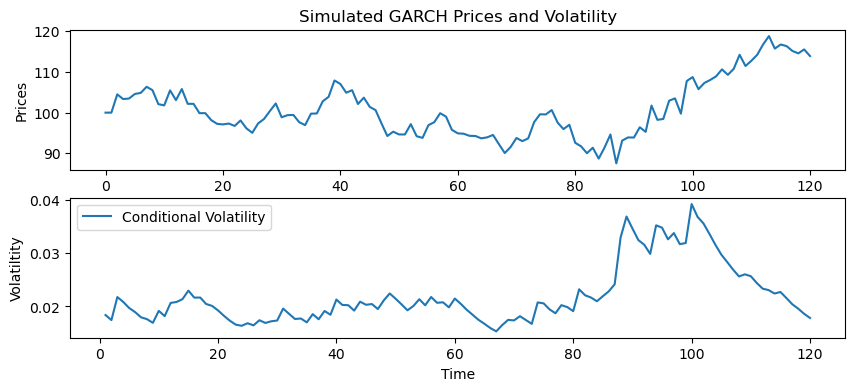

In [9]:
# 5) GARCH simulation
prices_garch, true_vol, returns = simulate_garch(
    n_steps=120,
    mu=0.0003,
    omega=0.00001,
    alpha=0.1,
    beta=0.87,
    start_price=100.0,
    n_paths=1,
    seed=42,
    burn=100,
)
print(prices_garch.head())
plt.figure(figsize=(10, 4))
plt.subplot(2,1,1)
plt.plot(prices_garch["Path_0"], label="Price")
plt.title("Simulated GARCH Prices and Volatility")
plt.xlabel("Time")
plt.ylabel("Prices")
plt.subplot(2,1,2)
plt.plot(true_vol["Path_0"], label="Conditional Volatility")
plt.xlabel("Time")
plt.ylabel("Volatiltity")
plt.legend()
plt.show()

{'mae': 1.4676269418257322, 'mse': 2.7312768890303163, 'rmse': 1.652657523212331}
     actual  forecast  step
0 -2.736023  0.007506     0
1  1.448902  0.002134     1
2  0.684983  0.010703     2
3  0.826847  0.017514     3
4  1.563198  0.024785     4
Fitted model type: ARCHModelResult


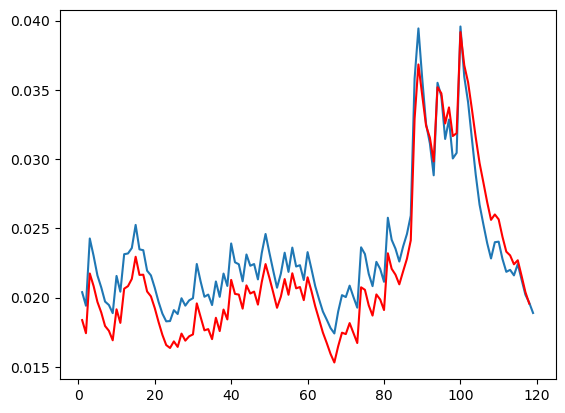

In [ ]:
# 6) Rolling-origin GARCH forecast
result, fitted_model = train_garch_rolling_forecast(
    returns * 100,
    initial_train_size=100,
    test_size=20,
    p=1,
    q=1,
)
print(result["metrics"])
print(result["forecast"].head())
print("Fitted model type:", type(fitted_model).__name__)
plt.plot(fitted_model.conditional_volatility/100)
plt.plot(true_vol.iloc[:119], color = "red")
plt.title("True volatility vs GARCH predicted volatility")